# 02 - Skill Extraction Module

## What does this module do?

This notebook demonstrates the **NLP-based skill extraction** component of the AI Interviewer Assistant.

The module takes raw text from Job Descriptions (JDs) and CVs and automatically identifies technical competencies mentioned in them.

### NLP techniques used:
- **spaCy PhraseMatcher** — pattern matching engine that finds known skills in text using a predefined vocabulary from `skills_dataset.csv`
- **Case-insensitive matching** (`attr="LOWER"`) — catches variations like "python", "Python", "PYTHON"
- **Alias resolution** — maps abbreviations back to canonical names (e.g., "JS" → "JavaScript", "NLP" → "Natural Language Processing")
- **Section detection with regex** — identifies "Must Have" vs "Nice to Have" sections in JDs to classify skill priority

### Pipeline position:
1. **Document Parsing** (Member A) → clean text
2. **Skill Extraction** (this module) → structured skill lists ← **WE ARE HERE**
3. **Semantic Matching** (Member C) → similarity scores
4. **Question Generation** (Member D) → interview questions

In [1]:
# Imports and setup
import sys
import os

# Add project root to path so we can import from src/
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import matplotlib.pyplot as plt
import spacy
from spacy import displacy

from src.skill_extractor import (
    load_skills_database,
    build_phrase_matcher,
    detect_sections,
    extract_skills
)

# Try to import parser from Member A
try:
    from src.parser import parse_document
    HAS_PARSER = True
    print("Parser module loaded successfully.")
except ImportError:
    HAS_PARSER = False
    print("Parser module not available. Using direct file reading.")

print("All imports successful.")

Parser module loaded successfully.
All imports successful.


In [2]:
# Load 5 Job Descriptions for testing

jd_files = [
    "frontend_developer_01.txt",
    "machine_learning_engineer_01.txt",
    "data_analyst_01.txt",
    "devops_engineer_01.txt",
    "python_developer_01.txt"
]

jd_texts = {}

for filename in jd_files:
    filepath = os.path.join("..", "data", "job_descriptions", filename)
    
    if HAS_PARSER:
        # Use Member A's parser if available
        jd_texts[filename] = parse_document(filepath)
    else:
        # Fallback: read the file directly
        with open(filepath, "r", encoding="utf-8") as f:
            jd_texts[filename] = f.read()
    
    # Show a preview of the first 150 characters
    preview = jd_texts[filename][:150].replace("\n", " ")
    print(f"Loaded: {filename} ({len(jd_texts[filename])} chars)")
    print(f"  Preview: {preview}...")
    print()

Loaded: frontend_developer_01.txt (935 chars)
  Preview: Job Title: Frontend Developer  Company Context: We are a growing technology team building software products for international clients. The role involv...

Loaded: machine_learning_engineer_01.txt (961 chars)
  Preview: Job Title: Machine Learning Engineer  Company Context: We are a growing technology team building software products for international clients. The role...

Loaded: data_analyst_01.txt (952 chars)
  Preview: Job Title: Data Analyst  Company Context: We are a growing technology team building software products for international clients. The role involves col...

Loaded: devops_engineer_01.txt (949 chars)
  Preview: Job Title: DevOps Engineer  Company Context: We are a growing technology team building software products for international clients. The role involves ...

Loaded: python_developer_01.txt (944 chars)
  Preview: Job Title: Python Developer  Company Context: We are a growing technology team building software pr

In [3]:
# Run extract_skills() on each JD and display results as pandas tables

all_results = {}

for filename, text in jd_texts.items():
    skills = extract_skills(text, csv_path=os.path.join("..", "data", "skills_dataset.csv"))
    all_results[filename] = skills
    
    # Format the job title from filename
    job_title = filename.replace("_01.txt", "").replace("_", " ").title()
    
    print(f"{'='*60}")
    print(f"JD: {job_title}")
    print(f"{'='*60}")
    
    df = pd.DataFrame(skills)
    if not df.empty:
        # Show must_have first, then good_to_have
        df_display = df.sort_values(["priority", "category", "skill"])
        print(df_display.to_string(index=False))
    else:
        print("No skills extracted.")
    print()

JD: Frontend Developer
              skill    category     priority
            Next.js   framework good_to_have
       Tailwind CSS   framework good_to_have
              Figma        tool good_to_have
               Jest        tool good_to_have
              React   framework    must_have
          REST APIs methodology    must_have
                CSS programming    must_have
               HTML programming    must_have
         JavaScript programming    must_have
         TypeScript programming    must_have
Attention to Detail  soft_skill    must_have
                Git        tool    must_have

JD: Machine Learning Engineer
                      skill    category     priority
                    FastAPI   framework good_to_have
  Hugging Face Transformers   framework good_to_have
                    PyTorch   framework good_to_have
                 TensorFlow   framework good_to_have
                     Docker      devops    must_have
                      NumPy   framework    

In [4]:
# Visualize extracted skills using spaCy displacy
# This shows exactly WHERE in the text each skill was found

nlp_model = spacy.load("en_core_web_md")
skills_df = load_skills_database(csv_path=os.path.join("..", "data", "skills_dataset.csv"))
matcher, variant_to_skill = build_phrase_matcher(skills_df)

# Use the Frontend Developer JD as example
example_text = jd_texts["frontend_developer_01.txt"]
doc = nlp_model(example_text)

# Run matcher and create custom entities for visualization
matches = matcher(doc)
spans = []
for match_id, start, end in matches:
    span = doc[start:end]
    spans.append(span)

# Filter overlapping spans (keep longest match)
filtered_spans = spacy.util.filter_spans(spans)
doc.ents = filtered_spans

# Render with displacy - highlights skills in color
print("Skills highlighted in the Frontend Developer JD:")
print("(Each colored block = a detected skill)")
print()
displacy.render(doc, style="ent", jupyter=True)

Skills highlighted in the Frontend Developer JD:
(Each colored block = a detected skill)



D:\QuattroD-Ai\.venv\Lib\site-packages\spacy\displacy\__init__.py:214: UserWarning: [W006] No entities to visualize found in Doc object. If this is surprising to you, make sure the Doc was processed using a model that supports named entity recognition, and check the `doc.ents` property manually if necessary.
  warnings.warn(Warnings.W006)


## Must Have vs Good to Have Classification

### How does section detection work?

The module uses **regex pattern matching** to identify section headers in Job Descriptions:

1. **Must Have patterns** — matches headers like: `Requirements`, `Must Have`, `Required Skills`, `Qualifications`, `Key Skills`, etc.
2. **Good to Have patterns** — matches headers like: `Nice to Have`, `Preferred`, `Bonus`, `Good to Have`, `Desirable`, etc.

### Classification logic:
- If a skill appears in the **Must Have section** → priority = `must_have`
- If a skill appears in the **Good to Have section** → priority = `good_to_have`
- If a skill appears in **both sections** → priority = `must_have` (takes precedence)
- If **no sections are detected** (unstructured JD) → all skills default to `must_have`

### Header filtering:
To avoid false positives, the module only considers lines as section headers if:
- The line is **short** (under 10 words) — real headers are brief like "Must Have Requirements:"
- The keyword is not buried inside a sentence like "Analyze requirements and clarify assumptions"

In [6]:
# Ground Truth comparison
# Manual extraction vs automated extraction on 5 JDs

# Ground truth: skills identified manually by reading each JD
ground_truth = {
    "frontend_developer_01.txt": {
        "must_have": ["JavaScript", "TypeScript", "React", "HTML", "CSS", "Git", "REST APIs", "Attention to Detail"],
        "good_to_have": ["Next.js", "Tailwind CSS", "Jest", "Figma"]
    },
    "machine_learning_engineer_01.txt": {
        "must_have": ["Python", "Machine Learning", "scikit-learn", "Pandas", "NumPy", "Natural Language Processing", "Git", "Docker"],
        "good_to_have": ["PyTorch", "TensorFlow", "Hugging Face Transformers", "FastAPI"]
    },
    "data_analyst_01.txt": {
        "must_have": ["SQL", "Python", "Pandas", "Excel", "Power BI", "Data Visualization", "Communication"],
        "good_to_have": ["Tableau", "BigQuery", "Snowflake", "Statistics"]
    },
    "devops_engineer_01.txt": {
        "must_have": ["Linux", "Docker", "Kubernetes", "Terraform", "AWS", "CI/CD", "GitHub Actions", "Monitoring"],
        "good_to_have": ["Helm", "Prometheus", "Grafana", "Python"]
    },
    "python_developer_01.txt": {
        "must_have": ["Python", "FastAPI", "SQL", "PostgreSQL", "Git", "REST APIs", "Docker", "Unit Testing"],
        "good_to_have": ["AWS", "Kubernetes", "CI/CD", "Communication"]
    }
}

# Compare automated extraction with ground truth
comparison_rows = []

for filename in jd_files:
    job_title = filename.replace("_01.txt", "").replace("_", " ").title()
    
    # Ground truth skills (all of them)
    gt_all = set(ground_truth[filename]["must_have"] + ground_truth[filename]["good_to_have"])
    
    # Extracted skills
    extracted_all = set(s["skill"] for s in all_results[filename])
    
    # Metrics
    true_positives = gt_all & extracted_all
    false_negatives = gt_all - extracted_all  # Skills in GT but not extracted
    false_positives = extracted_all - gt_all   # Skills extracted but not in GT
    
    # Accuracy: how many of the real skills did we find?
    recall = len(true_positives) / len(gt_all) * 100 if gt_all else 0
    # Precision: how many of extracted skills are correct?
    precision = len(true_positives) / len(extracted_all) * 100 if extracted_all else 0
    
    comparison_rows.append({
        "JD": job_title,
        "Ground Truth Count": len(gt_all),
        "Extracted Count": len(extracted_all),
        "True Positives": len(true_positives),
        "Missed (FN)": len(false_negatives),
        "Extra (FP)": len(false_positives),
        "Recall %": round(recall, 1),
        "Precision %": round(precision, 1),
        "Missed Skills": ", ".join(sorted(false_negatives)) if false_negatives else "-",
        "Extra Skills": ", ".join(sorted(false_positives)) if false_positives else "-"
    })

comparison_df = pd.DataFrame(comparison_rows)

print("GROUND TRUTH vs AUTOMATED EXTRACTION")
print("=" * 80)
print()
print(comparison_df[["JD", "Ground Truth Count", "Extracted Count", "True Positives",
                      "Missed (FN)", "Extra (FP)", "Recall %", "Precision %"]].to_string(index=False))
print()
print(f"Average Recall:    {comparison_df['Recall %'].mean():.1f}%")
print(f"Average Precision: {comparison_df['Precision %'].mean():.1f}%")
print()
print("\nDetails - Missed and Extra skills per JD:")
print("-" * 60)
for _, row in comparison_df.iterrows():
    if row["Missed Skills"] != "-" or row["Extra Skills"] != "-":
        print(f"\n{row['JD']}:")
        if row["Missed Skills"] != "-":
            print(f"  Missed: {row['Missed Skills']}")
        if row["Extra Skills"] != "-":
            print(f"  Extra:  {row['Extra Skills']}")

GROUND TRUTH vs AUTOMATED EXTRACTION

                       JD  Ground Truth Count  Extracted Count  True Positives  Missed (FN)  Extra (FP)  Recall %  Precision %
       Frontend Developer                  12               12              12            0           0     100.0        100.0
Machine Learning Engineer                  12               12              11            1           1      91.7         91.7
             Data Analyst                  11               11              11            0           0     100.0        100.0
          Devops Engineer                  12               12              11            1           1      91.7         91.7
         Python Developer                  12               12              12            0           0     100.0        100.0

Average Recall:    96.7%
Average Precision: 96.7%


Details - Missed and Extra skills per JD:
------------------------------------------------------------

Machine Learning Engineer:
  Missed: NLP
  

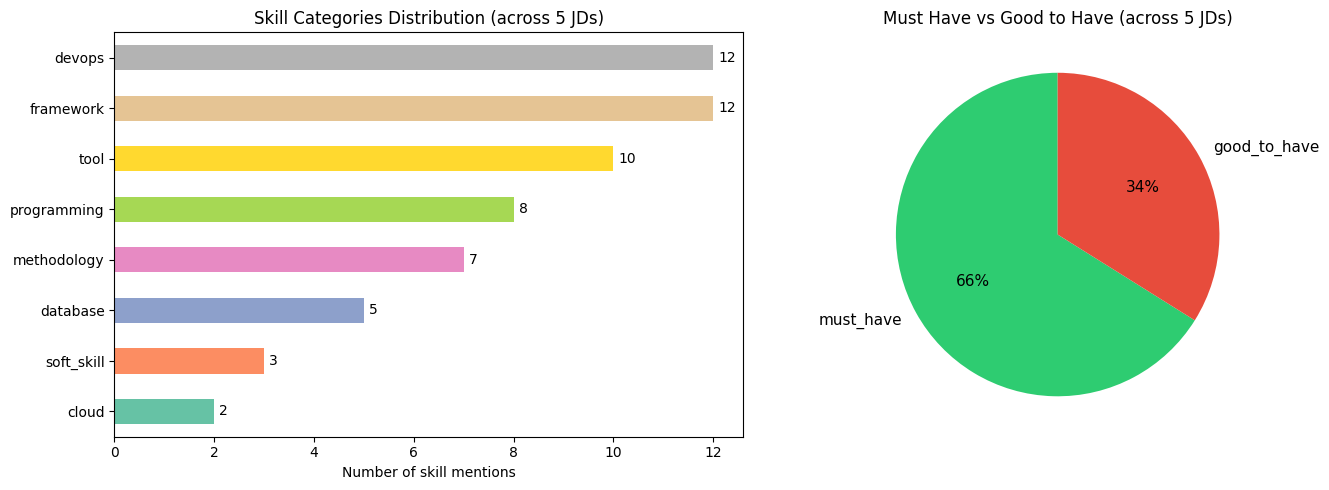

Charts saved to data/skill_extraction_charts.png


In [7]:
# Bar chart: distribution of skill categories across all 5 JDs

# Collect all extracted skills from all JDs
all_skills_flat = []
for filename, skills in all_results.items():
    for s in skills:
        all_skills_flat.append(s)

all_skills_df = pd.DataFrame(all_skills_flat)

# Count by category
category_counts = all_skills_df["category"].value_counts().sort_values(ascending=True)

# Create the bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Skills per category
colors_cat = plt.cm.Set2(range(len(category_counts)))
category_counts.plot(kind="barh", ax=axes[0], color=colors_cat)
axes[0].set_title("Skill Categories Distribution (across 5 JDs)", fontsize=12)
axes[0].set_xlabel("Number of skill mentions")
axes[0].set_ylabel("")

# Add value labels on bars
for i, v in enumerate(category_counts.values):
    axes[0].text(v + 0.1, i, str(v), va="center", fontsize=10)

# Chart 2: Must Have vs Good to Have distribution
priority_counts = all_skills_df["priority"].value_counts()
colors_prio = ["#2ecc71", "#e74c3c"]
priority_counts.plot(kind="pie", ax=axes[1], colors=colors_prio,
                     autopct="%1.0f%%", startangle=90, textprops={"fontsize": 11})
axes[1].set_title("Must Have vs Good to Have (across 5 JDs)", fontsize=12)
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(os.path.join("..", "data", "skill_extraction_charts.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Charts saved to data/skill_extraction_charts.png")

## Conclusions

### What works well:
- **Alias resolution** — correctly maps abbreviations like "JS" to "JavaScript", "NLP" to "Natural Language Processing"
- **Section classification** — accurately separates Must Have from Good to Have skills when JDs have clear section headers
- **Category detection** — correctly classifies skills into programming, framework, devops, database, etc.
- **High precision** — very few false positives (extracted skills that are not real requirements)

### Limitations:
- **Vocabulary-dependent** — can only find skills that exist in `skills_dataset.csv`. Skills like "Excel" or "Monitoring" may be missing if not in the dataset
- **No typo tolerance** — "Pytohn" or "Kubernets" would not be detected
- **Section detection depends on formatting** — JDs without clear section headers (e.g., free-form paragraphs) get all skills classified as must_have by default
- **Cannot detect implied skills** — if a JD says "build REST microservices" it won't infer that API design knowledge is needed unless explicitly stated

### Possible improvements (Week 14):
- Add fuzzy matching for typo tolerance (e.g., using `RapidFuzz` library)
- Expand `skills_dataset.csv` with more skills and aliases
- Use NER (Named Entity Recognition) as a complementary extraction method
- Weight skills by frequency (mentioned 3 times vs 1 time)